#### **Implementing Logistic Regression From Scratch using Numpy**

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

In [62]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Features: ", X.shape)
print("Target: ", y.shape)
print("Classes: ", data.target_names)

Features:  (569, 30)
Target:  (569,)
Classes:  ['malignant' 'benign']


In [63]:
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [64]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [65]:
# Since there are lot of features for simplicity, only keeping 2 columns and dropping others

X = df[['mean radius', 'mean texture']].values
y = df['target'].values

print("Features: ", X.shape)
print("Target: ", y.shape)

Features:  (569, 2)
Target:  (569,)


In [66]:
# Scaling

scalar = StandardScaler()

X = scalar.fit_transform(X)

print("Mean: ", X.mean(axis=0))
print("Standard Deviation: ", X.std(axis=0))

Mean:  [-1.37363271e-16  6.86816353e-17]
Standard Deviation:  [1. 1.]


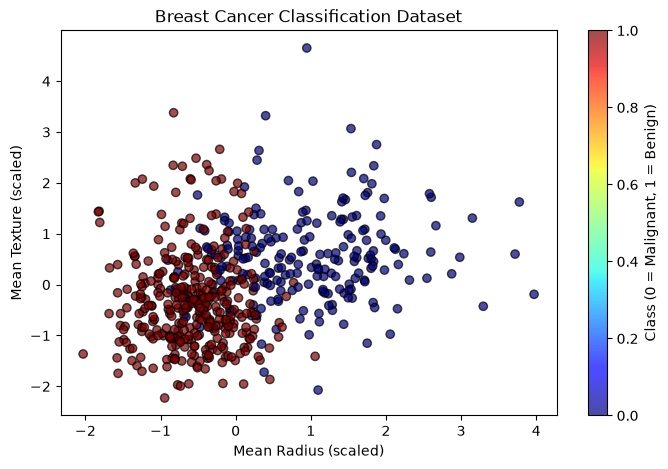

In [67]:
# Visualizing Dataset
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0], X[:, 1], c=y, cmap='jet', alpha=0.7, edgecolors='k'
)
plt.xlabel("Mean Radius (scaled)")
plt.ylabel("Mean Texture (scaled)")
plt.title("Breast Cancer Classification Dataset")
plt.colorbar(label="Class (0 = Malignant, 1 = Benign)")
plt.show()

In [68]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [69]:
def predict(X, w, b):
    z = np.dot(X, w) + b
    g = sigmoid(z)
    return g

In [ ]:
# Binary Cross Entropy / Logistic Loss
def cost_function(X, y, w, b):

    predictions = predict(X, w, b)

    epsilon = 1e-15
    predictions = np.clip(predictions, epsilon, 1 - epsilon)

    cost = -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))

    return cost

In [71]:
def gradient_descent(X, y, w, b, a, iterations):
    costs = []
    m = X.shape[0]

    for i in range(iterations):

        predictions = predict(X, w, b)
        errors = predictions - y
        dj_dw = np.dot(X.T, errors) / m
        dj_db = np.sum(errors) / m

        w = w - a * dj_dw
        b = b - a * dj_db

        costs.append(cost_function(X, y, w, b))

    return costs, w, b

In [72]:
# Training

w = np.zeros(X.shape[1])
b = 0.0
a = 0.1
iterations = 1000
cost_history, w , b = gradient_descent(
    X, y, w, b, a, iterations
)

print("Final Weight: ", w)
print("Final Bias: ", b)
print("Final Cost: ", cost_history[-1])

Final Weight:  [-3.34614224 -0.88791892]
Final Bias:  0.6998485790963043
Final Cost:  0.2568802076117608


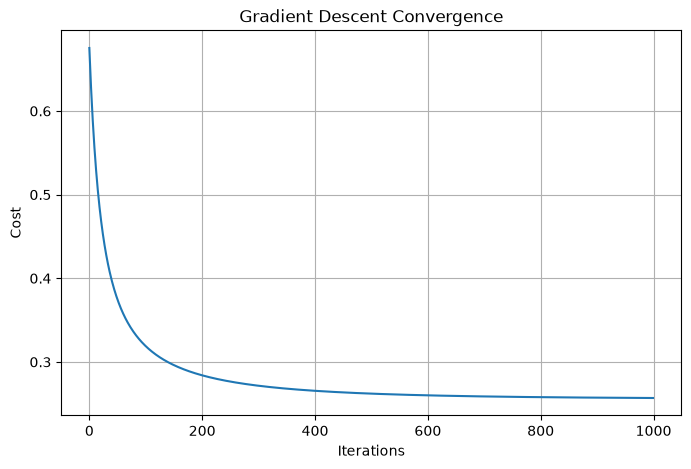

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.grid()
plt.show()

In [74]:
predictions = predict(X, w, b)

y_pred = (predictions >= 0.5).astype(int)

print("Actual Results: ", y[:10])
print("Predicted Results: ", y_pred[:10])

Actual Results:  [0 0 0 0 0 0 0 0 0 0]
Predicted Results:  [0 0 0 1 0 1 0 1 1 1]


In [75]:
accuracy = np.mean(y == y_pred) * 100
print(f"Training Accuracy: {accuracy:.2f}%")

Training Accuracy: 89.10%


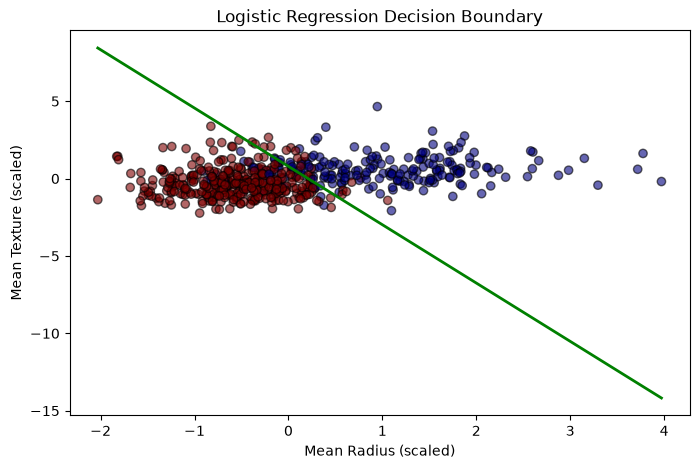

In [76]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0], X[:, 1], c=y, cmap='jet', alpha=0.6, edgecolors='k'
)

x_values = np.array([X[:, 0].min(), X[:, 0].max()])

if abs(w[1]) > 1e-10:
    y_values = -(w[0] * x_values + b) / w[1]
    plt.plot(x_values, y_values, 'g-', linewidth=2)

plt.xlabel("Mean Radius (scaled)")
plt.ylabel("Mean Texture (scaled)")
plt.title("Logistic Regression Decision Boundary")
plt.show()